In [1]:

from scipy.sparse import load_npz
from pathlib import Path

import pandas as pd
import numpy as np
import re

from sklearn.cluster import DBSCAN

from sklearn.metrics import silhouette_score
from sklearn.model_selection import ParameterGrid

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity

import joblib
import plotly.express as px
import matplotlib.pyplot as plt

In [2]:
processed_dir = Path(r'C:\Users\LN\Documents\Jedha\Projets\NORTH_FACE\Helene\data\processed')

tfidf_unigram_matrix = load_npz(processed_dir / "tfidf_unigram_matrix.npz")
tfidf_sublinear_matrix = load_npz(processed_dir / "tfidf_sublinear_matrix.npz")
tfidf_bigram_matrix = load_npz(processed_dir / "tfidf_bigram_matrix.npz")
ids = pd.read_csv(processed_dir / "tfidf_row_ids.csv")
df = pd.read_csv(processed_dir / "sample_clean.csv")

# Il faut s'assurer que la matrice TF-IDF et les identifiants des lignes correspondent
# bien aux produits du DataFrame original.
assert tfidf_bigram_matrix.shape[0] == len(ids)
assert tfidf_unigram_matrix.shape[0] == len(df)
assert tfidf_sublinear_matrix.shape[0] == len(df)
assert ids["id"].is_unique
assert ids["id"].equals(df["id"])

In [3]:
print("Shape :", tfidf_bigram_matrix.shape)
print("Shape :", tfidf_unigram_matrix.shape)
print("Shape :", tfidf_sublinear_matrix.shape)

Shape : (500, 8059)
Shape : (500, 2036)
Shape : (500, 2036)


Le cluster -1 est le cluster considéré comme du bruit par l'algorithme Dbscan. Nous allons tenter de réduire le nombre de produits dans ce cluster en ajustant les paramètres de l'algorithme.

In [4]:
results = []

for tfidf_matrix, matrix_name in [
    (tfidf_unigram_matrix, "unigram"),
    (tfidf_sublinear_matrix, "sublinear"),
    (tfidf_bigram_matrix, "bigram")
]:
    print(f"Analyse pour la matrice TF-IDF : {matrix_name}")
    parameters = {
        "eps": np.round(np.arange(0.20, 0.98, 0.01), 2),
        "min_samples": [3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20, 25, 30, 50]
    }

    for params in ParameterGrid(parameters):
        labels_test = DBSCAN(
            **params,
            metric="cosine"
        ).fit_predict(tfidf_matrix)

        without_noise = labels_test != -1
        sizes = pd.Series(labels_test[without_noise]).value_counts()
        clusters_nb = len(sizes)

        score = np.nan
        if 2 <= clusters_nb < without_noise.sum():
            score = silhouette_score(
                tfidf_matrix[without_noise],
                labels_test[without_noise],
                metric="cosine"
            )

        results.append({
            "representation": matrix_name,
            **params,
            "silhouette": score,
            "noise_pct": (~without_noise).mean() * 100,
            "clusters_nb": clusters_nb,
            "min_size": sizes.min() if clusters_nb else 0,
            "%_biggest_cluster": (
                sizes.max() / sizes.sum() * 100
                if clusters_nb else np.nan
            )
        })

results = pd.DataFrame(results)

Analyse pour la matrice TF-IDF : unigram
Analyse pour la matrice TF-IDF : sublinear
Analyse pour la matrice TF-IDF : bigram


In [5]:
display(results.sort_values("silhouette", ascending=False).head(10))

,representation,eps,min_samples,silhouette,noise_pct,clusters_nb,min_size,%_biggest_cluster
2215,bigram,0.22,6,0.882818,97.2,2,6,57.142857
2201,bigram,0.21,6,0.882818,97.2,2,6,57.142857
2187,bigram,0.20,6,0.882818,97.2,2,6,57.142857
2200,bigram,0.21,5,0.880670,96.2,3,5,42.105263
2186,bigram,0.20,5,0.880670,96.2,3,5,42.105263
2185,bigram,0.20,4,0.875264,93.8,6,4,25.806452
2184,bigram,0.20,3,0.865745,89.6,13,3,15.384615
2229,bigram,0.23,6,0.863772,96.0,3,6,40.000000
2214,bigram,0.22,5,0.863772,96.0,3,6,40.000000
2199,bigram,0.21,4,0.863573,93.6,6,4,25.000000


In [6]:
candidates = results[(results["clusters_nb"] <= 20) & (results["clusters_nb"] >= 10) & results["silhouette"].notna()]

In [7]:
display(candidates.sort_values("silhouette", ascending=False).head(10))

,representation,eps,min_samples,silhouette,noise_pct,clusters_nb,min_size,%_biggest_cluster
2184,bigram,0.20,3,0.865745,89.6,13,3,15.384615
1092,sublinear,0.20,3,0.842318,89.0,14,3,14.545455
0,unigram,0.20,3,0.834023,86.8,14,3,19.696970
14,unigram,0.21,3,0.834023,86.8,14,3,19.696970
2198,bigram,0.21,3,0.833715,88.2,15,3,13.559322
1148,sublinear,0.24,3,0.822625,87.4,14,3,20.634921
28,unigram,0.22,3,0.816334,86.2,15,3,18.840580
2268,bigram,0.26,3,0.814439,85.0,17,3,17.333333
1162,sublinear,0.25,3,0.808647,87.0,14,3,20.000000
42,unigram,0.23,3,0.803890,85.8,15,3,18.309859


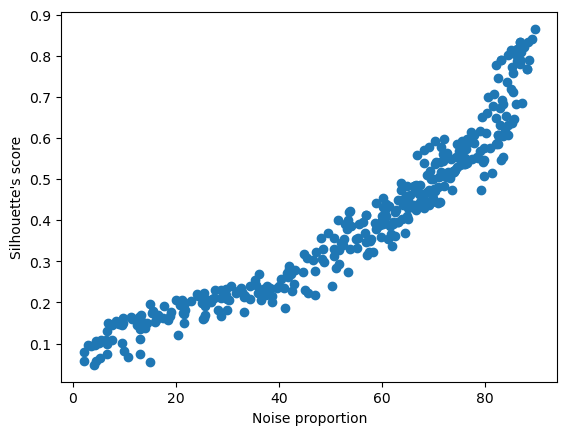

In [8]:
plt.scatter(candidates["noise_pct"], candidates["silhouette"])
plt.xlabel("Noise proportion")
plt.ylabel("Silhouette's score")
plt.show()

In [9]:
candidates = results.loc[
    results["clusters_nb"].between(10, 20)
    & results["silhouette"].notna()
].copy()

if candidates.empty:
    print("Aucun candidat dans la plage 10–20 clusters.")
    # display(results)
else:
    # display(candidates.sort_values(
    #     ["noise_pct", "silhouette"],
    #     ascending=[True, False]
    # ))

    fig = px.scatter(
        candidates,
        x="noise_pct",
        y="silhouette",
        color="%_biggest_cluster",
        hover_data=[
            "eps", "min_samples",
            "clusters_nb", "min_size"
        ],
        title="DBSCAN — compromis entre bruit et silhouette"
    )
    fig.show()

étant donné la relation entre le score de silhouette et le pourcentage de produits dans le cluster -1, nous allons filtrer les résultats pour ne conserver que ceux qui ont un score de silhouette raisonnable et un pourcentage de produits dans le cluster -1 optimisé en limitant le nombre de produits dans le cluster dominant.

1. La couverture du dbscan :

In [10]:
candidates = candidates.loc[
    candidates["noise_pct"].between(0, 65)
    & (candidates["min_size"] > 5)
].sort_values("noise_pct", ascending=True)

In [11]:
candidates.loc[results["silhouette"].between(0.2, 1)].sort_values("noise_pct", ascending=True)

,representation,eps,min_samples,silhouette,noise_pct,clusters_nb,min_size,%_biggest_cluster
647,unigram,0.66,6,0.202285,23.0,14,6,40.000000
2929,bigram,0.73,6,0.208400,25.6,17,6,27.688172
1767,sublinear,0.68,6,0.208200,27.0,18,6,30.410959
648,unigram,0.66,7,0.211886,28.8,12,7,40.449438
1753,sublinear,0.67,6,0.218843,29.8,18,6,29.629630
...,...,...,...,...,...,...,...,...
2832,bigram,0.66,7,0.368337,64.4,10,7,33.146067
437,unigram,0.51,6,0.458614,64.6,13,6,31.073446
2775,bigram,0.62,6,0.409899,64.8,12,6,33.522727
1599,sublinear,0.56,6,0.430838,65.0,13,6,32.000000


In [12]:
final = (
    candidates.loc[
        candidates["silhouette"].ge(0.2)
        & candidates["min_size"].ge(6)
        & candidates["clusters_nb"].between(10, 20)
    ]
    .sort_values(
        ["noise_pct", "silhouette"],
        ascending=[True, False]
    )
    .groupby("representation", sort=False)
    .head(1)
    .copy()
)

display(final)

,representation,eps,min_samples,silhouette,noise_pct,clusters_nb,min_size,%_biggest_cluster
647,unigram,0.66,6,0.202285,23.0,14,6,40.000000
2929,bigram,0.73,6,0.208400,25.6,17,6,27.688172
1767,sublinear,0.68,6,0.208200,27.0,18,6,30.410959


In [13]:
tfidf_matrix = {
    "unigram": tfidf_unigram_matrix,
    "sublinear": tfidf_sublinear_matrix,
    "bigram": tfidf_bigram_matrix,
}

In [14]:
final_results = {}

for representation in final["representation"].unique():
    print(f"Analyse pour la matrice TF-IDF : {representation}")
    dbscan_candidate = DBSCAN(
        eps=final.loc[
            final["representation"] == representation, "eps"
        ].values[0],
        min_samples=final.loc[
            final["representation"] == representation, "min_samples"
        ].values[0],
        metric="cosine"
    )

    labels_candidate = dbscan_candidate.fit_predict(tfidf_matrix[representation])
    reading_candidate = ids.assign(
        cluster=labels_candidate
    ).merge(
        df[["id", "description_text"]],
        on="id",
        how="left",
        validate="one_to_one"
    )

    sizes = reading_candidate.loc[
        reading_candidate["cluster"] != -1, "cluster"
    ].value_counts()

    display(sizes.rename("nombre de produits"))

    biggest = sizes.idxmax()
    group = reading_candidate.loc[
        reading_candidate["cluster"] == biggest
    ]
    final_results[representation] = {
        "dbscan": dbscan_candidate,
        "labels": labels_candidate,
        "reading": reading_candidate,
        "biggest_cluster": biggest,
        "products_biggest_cluster": group,
        "size_biggest_cluster": sizes.max(),
        "pct_biggest_cluster": sizes.max() / sizes.sum() * 100
    }

Analyse pour la matrice TF-IDF : unigram


cluster
0     154
4      59
3      46
1      27
11     16
12     15
8      15
2       9
7       9
9       8
5       8
10      7
6       6
13      6
Name: nombre de produits, dtype: int64

Analyse pour la matrice TF-IDF : bigram


cluster
3     103
5      59
4      39
0      27
1      26
16     24
11     15
8      14
2      10
10      9
7       8
15      7
13      7
9       6
12      6
14      6
6       6
Name: nombre de produits, dtype: int64

Analyse pour la matrice TF-IDF : sublinear


cluster
1     111
4      59
0      46
2      28
9      15
13     11
10     10
8       9
3       9
14      9
16      9
5       8
6       8
11      8
12      7
7       6
17      6
15      6
Name: nombre de produits, dtype: int64

In [15]:
final_results

{'unigram': {'dbscan': DBSCAN(eps=np.float64(0.66), metric='cosine', min_samples=np.int64(6)),
  'labels': array([ 3, -1,  3,  0,  0,  0,  1,  2,  0,  0, -1,  0,  9, 11,  0,  0, -1,
          3,  3,  3,  3,  3,  3,  3,  3,  4,  0,  0,  0,  0,  1,  0,  0,  0,
          0,  4,  0, -1, -1, -1,  4,  1,  0,  0, -1,  0, 12,  5, -1, -1,  0,
         -1,  1,  1,  1,  4, -1,  4,  0,  3,  3, -1,  4,  4,  4, 11,  0,  4,
          5,  0,  4,  4,  4,  9,  6, -1,  6, -1,  7,  7,  7, -1,  1,  1,  0,
          0,  8,  8,  8,  8,  0,  0,  1,  1,  4,  0,  0,  4, -1,  0, -1,  4,
          4,  1,  3,  3,  0,  0,  0,  0, -1, -1, -1, -1,  0,  4,  3,  0,  0,
          0, -1,  4, -1,  4, -1, -1,  0, -1,  0, -1,  1, -1, -1, -1,  9, -1,
         -1,  4,  4, -1,  0, -1,  0,  4, -1,  0,  0,  7,  9, 10,  4,  4, 10,
         10, -1, -1,  0, -1,  0, 11, 11, 12,  0, -1, -1, 11,  4,  0,  4,  4,
          3,  3,  3,  3,  3,  3,  4,  4,  0, 11, -1, -1, 12,  0,  4,  0,  0,
          0,  0,  0,  0,  0,  0,  0,  6,  3,  0,

In [16]:
projection_2d = TruncatedSVD(n_components=2, random_state=42)

## 1. Analyse des résultats DScan de la première représentation : Sublinear TF-IDF

In [17]:
resultat_sublinear = pd.DataFrame([final_results["sublinear"]])

In [18]:
labels = final_results["sublinear"]["labels"]

In [19]:
coordinates = projection_2d.fit_transform(tfidf_sublinear_matrix)
visualisation = pd.DataFrame({
    "SVD 1": coordinates[:, 0],
    "SVD 2": coordinates[:, 1],
    "id": ids["id"].to_numpy(),
    "cluster": [
        "Noise" if label == -1 else f"Cluster {label}"
        for label in labels
    ]
})

In [20]:
cores = np.zeros(len(labels), dtype=bool)
cores[dbscan_candidate.core_sample_indices_] = True

visualisation["status"] = np.where(
    labels == -1,
    "Noise",
    np.where(cores, "Core", "Border")
)

fig = px.scatter(
    visualisation,
    x="SVD 1",
    y="SVD 2",
    color="cluster",
    symbol="status",
    symbol_map={"Core": "circle", "Border": "diamond", "Noise": "x"},
    color_discrete_map={"Noise": "lightgray"},
    hover_data=["id", "status"],
    opacity=0.7,
    title="DBSCAN — clusters et vrais points cœur",
    height=600,
    width=600
)

fig.show()

In [21]:
tsne = TSNE(
    n_components=2,
    metric="cosine",
    perplexity=30,
    init="random",
    learning_rate="auto",
    random_state=42
)

coord_tsne = tsne.fit_transform(tfidf_sublinear_matrix.toarray())

visu_tsne = visualisation.copy()
visu_tsne["t-SNE 1"] = coord_tsne[:, 0]
visu_tsne["t-SNE 2"] = coord_tsne[:, 1]

fig = px.scatter(
    visu_tsne,
    x="t-SNE 1",
    y="t-SNE 2",
    color="cluster",
    symbol="status",
    symbol_map={"Core": "circle", "Border": "diamond", "Noise": "x"},
    color_discrete_map={"Noise": "lightgray"},
    hover_data=["id", "status"],
    opacity=0.7,
    title="DBSCAN — visualisation t-SNE, distance cosinus",
    height=600,
    width=600
)

fig.show()

In [22]:
tsne_3d = TSNE(
    n_components=3,
    metric="cosine",
    perplexity=30,
    init="random",
    learning_rate="auto",
    random_state=42
)

coord_3d = tsne_3d.fit_transform(tfidf_sublinear_matrix.toarray())

visu_3d = visualisation.copy()
visu_3d[["t-SNE 1", "t-SNE 2", "t-SNE 3"]] = coord_3d

fig = px.scatter_3d(
    visu_3d,
    x="t-SNE 1",
    y="t-SNE 2",
    z="t-SNE 3",
    color="cluster",
    symbol="status",
    symbol_map={"Core": "circle", "Border": "diamond", "Noise": "x"},
    color_discrete_map={"Noise": "lightgray"},
    hover_data=["id", "status"],
    opacity=0.7,
    title="DBSCAN — projection t-SNE en 3D",
    height=600,
    width=600
)

fig.update_traces(marker_size=4)
fig.update_layout(scene_aspectmode="data")
fig.show()

In [23]:
vectorizer = joblib.load("../models/tfidf_sublinear_vectorizer.joblib")
words = vectorizer.get_feature_names_out()

# Retrouver les descriptions dans l'ordre exact de la matrice
source = pd.read_csv(
    processed_dir / "sample_clean.csv"
).set_index("id")

reading = ids.copy()
reading["cluster"] = labels
reading["text"] = source.loc[
    ids["id"], "description_text"
].to_numpy()

assert tfidf_sublinear_matrix.shape == (len(reading), len(words))


In [24]:
cluster_ids = np.unique(labels[labels != -1]) # Parcours tous les clusters sauf le bruit (-1)

for cluster_id in cluster_ids:
    mask = labels == cluster_id
    assert cluster_id != -1 and mask.any()

    X_cluster = tfidf_sublinear_matrix[mask]

    # weight TF-IDF moyen de chaque mot dans ce groupe
    weight = np.asarray(X_cluster.mean(axis=0)).ravel()
    top = np.argsort(weight)[::-1][:12]
    top = top[weight[top] > 0]

    words_cluster = pd.DataFrame({
        "word": words[top],
        "Mean weight TF-IDF": weight[top]
    })

    fig = px.bar(
        words_cluster,
        x="Mean weight TF-IDF",
        y="word",
        orientation="h",
        title=f"Cluster {cluster_id} — dominants words",
        height=400,
        width=600
    )
    fig.update_yaxes(categoryorder="total ascending")
    fig.show()

    # Descriptions les plus proches du centre moyen en distance cosinus
    center = np.asarray(X_cluster.mean(axis=0))
    similarites = cosine_similarity(X_cluster, center).ravel()

    positions = np.flatnonzero(mask)
    selection = positions[np.argsort(similarites)[::-1][:3]]

    print(f"Cluster {cluster_id} : {len(positions)} products")

    with pd.option_context("display.max_colwidth", None):
        display(reading.iloc[selection][["id", "text"]])

Cluster 0 : 46 products


,id,text
496,497,"cap 2 crew - this crew takes the edge off fickle weather. in clearing conditions, it has the fastest dry time of all our performance baselayer fabrics, with an open-knit construction that breathes and wicks to keep you dry and cool. when the weather window shuts, you can wear it as insulation beneath layers. with a self-fabric neck that s soft against the skin, and raglan sleeves and flat-ribbed underarm panels that merge out of the way of shoulder straps to eliminate chafe. made from 4-oz 100 % polyester 54% recycled with gladiodor natural odor control for the garment. recyclable through the common threads recycling program."
440,441,"cap 3 crew - capilene 3, the most versatile and fastest-wicking of our performance baselayer fabrics, helps you stay dry and warm. this crew provides excellent insulation and has a dense interior honeycomb grid that s brushed for warmth, softness and compressibility. its smooth jersey exterior glides readily beneath layers. raglan sleeves and single-piece shoulder panels merge out of the way of shoulder straps, and side panels are offset to eliminate chafe. made from 4.8-oz 100% polyester 64% recycled with gladiodor natural odor control for the garment. recyclable through the common threads recycling program."
21,22,"cap 2 t-shirt - this one revels in the sweat jamborees of hill climbs, ridge runs and desert singletrack under a resolute sun. made from the fastest-drying of our performance baselayer fabrics, it has an open knit that invites airflow and provides excellent wicking and exceptional breathability. when worn beneath layers, it s also insulative enough for chilly days. the self-binding neck is pliable and soft raglan sleeves and flat-ribbed underarm panels merge out of the way of straps to eliminate chafe. made of 4-oz 100% polyester 54% recycled with gladiodor natural odor control for the garment. recyclable through the common threads recycling program."


Cluster 1 : 111 products


,id,text
329,330,"borderless zip-off pants - worn as capris on one side of the border and pants on the other, these versatile hybrids are practically bilingual. made of a moisture-wicking a nylon/spandex fabric blend with built-in 40-upf sun protection, they re lightweight and dry in a jiffy. with a zip fly and double-snap closure waistband, two front patch pockets, two welted, mesh-lined back pockets and a phone-fitting leg pocket. articulated knee patches add mobility. pants inseam size 8 is 32 capris, 18 . recyclable through the common threads recycling program."
213,214,"rock guide shorts - tough, abrasion-resistant rock guides are known to withstand butt-slide descents of the joshua tree classic, clean and jerk. made of a technical stretch-woven nylon that s soft on the skin and dries quickly, the shorts have a zip fly, gusseted crotch, front drop-in pockets, a single zippered thigh pocket and rear security pockets. regular rise inseam size 8 is 9 . recyclable through the common threads recycling program."
342,343,"rock guide pants - first and foremost, these lightweight, soft, stretch-woven nylon pants with 2-way stretch serve a primary purpose climbing. they have articulated knees and a gusseted crotch to match body dynamics and a 2-way zippered fly for hassle-free relief while wearing a harness. the athletic not baggy cut includes straight lower legs with a wide hem, making for easy-to-roll-up cuffs that stay in place through footwork-intensive routes. the button waist has belt loops and a brushed interior for next-to-skin comfort. pockets include two handwarmers, one rear zippered hip and one stitched-on zippered thigh. with 40-upf sun protection. inseam size 32 is 32 . recyclable through the common threads recycling program."


Cluster 2 : 28 products


,id,text
353,354,"single shot - the single shot organizes your daily necessities with its thoughtful, efficient design. a simple flap with hook-and-loop closure accesses a main compartment that has a zippered mesh pocket two organizer pockets one with an internal security pocket keep smaller gear at your fingertips. an easy-access document sleeve holds airline tickets, reading material or a notebook. the long, adjustable shoulder strap and top-mounted carry handle make the bag both comfortable and convenient to haul. made from 150-denier all-recycled polyester double weave with a polyurethane coating and a dwr durable water repellent finish."
463,464,"daily grind - this fully padded shoulder bag keeps you moving unchallenged through the daily grind. with a minimalist design, it protects a 17 or smaller laptop and helps you stay organized. the main pocket has a stretch-woven internal sleeve and is accessed by a simple flap with hook-and-loop closure. two organizer pockets one with a zippered security pocket keep smaller gear at your fingertips, and an easy-access document sleeve holds airline tickets, reading material or a notebook. carry it with the long, adjustable shoulder strap or top-mounted handle. made from 150-denier all-recycled polyester double weave with a polyurethane coating and a dwr durable water repellent finish."
30,31,"crosstown - crosstown or cross-country, this fully featured commuter backpack ensures that your life stays organized whether you re office-bound, hiking the steep and narrow, or somewhere in the global commute. inside its zippered main compartment, it features a suspended, self-adjusting padded laptop sleeve that handles a 15 to 17 laptop. a secondary zippered compartment opens to a portable office organizer system. with a front catch-all sleeve with hidden zipper that provides easy access to documents a stretch-woven water-bottle pocket and a fleece-lined top pocket that protects sunglasses or electronics 3-d spacer-mesh backpack straps and back padding for comfort and breathability an adjustable sternum strap with built-in safety whistle. made from 150-denier all-recycled polyester double weave with a polyurethane coating and a dwr durable water repellent finish."


... (26 outputs left out)

Cluster 16 : 9 products


,id,text
309,310,"astrid top - the delicately feminine astrid top is a refreshing change from the heavy-lipped poundings of a big south swell. made from our lightest weight blend of organic cotton and tencel jersey 55%/45% fabric, the short-sleeved top has a gathered scoop neck for a flattering fit and drape. the ultrasoft shirt falls at the hip. recyclable through the common threads recycling program."
297,298,versatiliti tank - vivid colors and delicate details enliven this season s crop of versatiliti tanks. made of a lightweight blend of 62% organic cotton/38% tencel that line-dries over night. it has a flattering v-neck and slightly gathered shoulders with a center back seam for a contoured fit. recyclable through the common threads recycling program.
295,296,"versatili-tee - at the top of the t-shirt food chain, the versatili-tee has satin-stitch finishing and a sensuous drape that humbles the competition. the plaited blend of organic cotton and tencel has a soft hand and natural stretch. recyclable through the common threads recycling program."


Cluster 17 : 6 products


,id,text
465,466,"baby baggies shorts - about 70% of the planet is covered in water, and our amphibious baggies are built for all of it. these soft, quick-drying shorts have a 4-ply, 4.2-oz supplex nylon fabric with a dwr durable water repellent finish that sheds water and makes cleanups easy. with an elasticized waistband for a comfortable fit, and a little extra room in the backside to cover a diaper. inseam is 3 . recyclable through the common threads recycling program."
427,428,"girl s baggies shorts - an everyday staple for the beach and long summer days, our lightweight, durable girls baggies have a 3 inseam and a more feminine fit than traditional baggies. other than that, they re built to shred 4-ply, 4.2-oz supplex nylon with a dwr durable water repellent finish stays unsoggy in rapids and surf, and dries in a flash. self-draining mesh pockets prevent ballooning the elasticized drawstring waist brushed inside for comfort holds on during a tumult. recyclable through the common threads recycling program."
407,408,"baggies shorts - summertime unwinds in a boisterous flurry of kids, dogs, sunshine and water. our do-all, go-all baggies shorts flow effortlessly from chaos to quiet times with an easy-going feel. they re made from lightweight, quick-to-dry 4-ply, 4.2-oz supplex nylon with a dwr durable water repellent finish to shed water. self-draining, half-mesh pockets are bartacked at all stress points. the fully elasticized drawcord waist holds onto beanpole hips and has a self-fabric backing for no-chafe comfort. with a built-in mesh liner. inseam is 6 . recyclable through the common threads recycling program."


## 2. Analyse des résultats DScan de la première représentation : Unigrammes TF-IDF

In [25]:
resultat_unigram = pd.DataFrame([final_results["unigram"]])

In [26]:
labels = final_results["unigram"]["labels"]
coordinates = projection_2d.fit_transform(tfidf_unigram_matrix)
visualisation = pd.DataFrame({
    "SVD 1": coordinates[:, 0],
    "SVD 2": coordinates[:, 1],
    "id": ids["id"].to_numpy(),
    "cluster": [
        "Noise" if label == -1 else f"Cluster {label}"
        for label in labels
    ]
})
cores = np.zeros(len(labels), dtype=bool)
cores[dbscan_candidate.core_sample_indices_] = True

visualisation["status"] = np.where(
    labels == -1,
    "Noise",
    np.where(cores, "Core", "Border")
)

fig = px.scatter(
    visualisation,
    x="SVD 1",
    y="SVD 2",
    color="cluster",
    symbol="status",
    symbol_map={"Core": "circle", "Border": "diamond", "Noise": "x"},
    color_discrete_map={"Noise": "lightgray"},
    hover_data=["id", "status"],
    opacity=0.7,
    title="DBSCAN — clusters et vrais points cœur",
    height=600,
    width=600
)

fig.show()

In [27]:

tsne = TSNE(
    n_components=2,
    metric="cosine",
    perplexity=30,
    init="random",
    learning_rate="auto",
    random_state=42
)

coord_tsne = tsne.fit_transform(tfidf_unigram_matrix.toarray())

visu_tsne = visualisation.copy()
visu_tsne["t-SNE 1"] = coord_tsne[:, 0]
visu_tsne["t-SNE 2"] = coord_tsne[:, 1]

fig = px.scatter(
    visu_tsne,
    x="t-SNE 1",
    y="t-SNE 2",
    color="cluster",
    symbol="status",
    symbol_map={"Core": "circle", "Border": "diamond", "Noise": "x"},
    color_discrete_map={"Noise": "lightgray"},
    hover_data=["id", "status"],
    opacity=0.7,
    title="DBSCAN — visualisation t-SNE, distance cosinus",
    height=600,
    width=600
)

fig.show()

In [28]:
tsne_3d = TSNE(
    n_components=3,
    metric="cosine",
    perplexity=30,
    init="random",
    learning_rate="auto",
    random_state=42
)

coord_3d = tsne_3d.fit_transform(tfidf_unigram_matrix.toarray())

visu_3d = visualisation.copy()
visu_3d[["t-SNE 1", "t-SNE 2", "t-SNE 3"]] = coord_3d

fig = px.scatter_3d(
    visu_3d,
    x="t-SNE 1",
    y="t-SNE 2",
    z="t-SNE 3",
    color="cluster",
    symbol="status",
    symbol_map={"Core": "circle", "Border": "diamond", "Noise": "x"},
    color_discrete_map={"Noise": "lightgray"},
    hover_data=["id", "status"],
    opacity=0.7,
    title="DBSCAN — projection t-SNE en 3D",
    height=600,
    width=600
)

fig.update_traces(marker_size=4)
fig.update_layout(scene_aspectmode="data")
fig.show()

In [29]:
vectorizer = joblib.load("../models/tfidf_unigram_vectorizer.joblib")
words = vectorizer.get_feature_names_out()

# Retrouver les descriptions dans l'ordre exact de la matrice
source = pd.read_csv(
    processed_dir / "sample_clean.csv"
).set_index("id")

reading = ids.copy()
reading["cluster"] = labels
reading["text"] = source.loc[
    ids["id"], "description_text"
].to_numpy()

assert tfidf_unigram_matrix.shape == (len(reading), len(words))

In [30]:
cluster_ids = np.unique(labels[labels != -1]) # Parcours tous les clusters sauf le bruit (-1)

for cluster_id in cluster_ids:
    mask = labels == cluster_id
    assert cluster_id != -1 and mask.any()

    X_cluster = tfidf_unigram_matrix[mask]

    # weight TF-IDF moyen de chaque mot dans ce groupe
    weight = np.asarray(X_cluster.mean(axis=0)).ravel()
    top = np.argsort(weight)[::-1][:12]
    top = top[weight[top] > 0]

    words_cluster = pd.DataFrame({
        "word": words[top],
        "Mean weight TF-IDF": weight[top]
    })

    fig = px.bar(
        words_cluster,
        x="Mean weight TF-IDF",
        y="word",
        orientation="h",
        title=f"Cluster {cluster_id} — dominants words",
        height=400,
        width=600
    )
    fig.update_yaxes(categoryorder="total ascending")
    fig.show()

    # Descriptions les plus proches du centre moyen en distance cosinus
    center = np.asarray(X_cluster.mean(axis=0))
    similarities = cosine_similarity(X_cluster, center).ravel()

    positions = np.flatnonzero(mask)
    selection = positions[np.argsort(similarities)[::-1][:3]]

    print(f"Cluster {cluster_id} : {len(positions)} products")

    with pd.option_context("display.max_colwidth", None):
        display(reading.iloc[selection][["id", "text"]])

Cluster 0 : 154 products


,id,text
213,214,"rock guide shorts - tough, abrasion-resistant rock guides are known to withstand butt-slide descents of the joshua tree classic, clean and jerk. made of a technical stretch-woven nylon that s soft on the skin and dries quickly, the shorts have a zip fly, gusseted crotch, front drop-in pockets, a single zippered thigh pocket and rear security pockets. regular rise inseam size 8 is 9 . recyclable through the common threads recycling program."
28,29,"continental shorts - wrinkle-resistant travel shorts that do what any great mountainside-to-museum garment should wick moisture, dry quickly, and look sharp after successive days of use. the continentals deploy our classic guide fabric - a tough, agile blend of 53% polyester and 47% nylon with a dwr durable water repellent finish. details include drop-in front pockets and two cargo and two rear pockets each with one zipper closure and one hook-and-loop velcro closure . regular fit inseam size 32 is 10 1/2 . recyclable through the common threads recycling program."
14,15,"borderless shorts-11 in. - go forward where others cringe. our borderless shorts are made for prying into the outer reaches of unnamed terrain. they have a light, breathable fabric that blends 95% nylon 60% recycled with 5% spandex mini ripstop to resist the effects of thrashy chimneys and provide stretch for the body language of going places. the dwr durable water repellent finish shrugs off water built-in 40-upf sun protection shades your legs in open country. other features include a gusseted crotch to preserve mobility, two front pockets you can access while wearing a harness and a partially elastic waist to keep your shorts adhered under the load of a hip belt. the rear welted pockets secure with zips. inseam size m is 11 . recyclable through the common threads recycling program."


Cluster 1 : 27 products


,id,text
353,354,"single shot - the single shot organizes your daily necessities with its thoughtful, efficient design. a simple flap with hook-and-loop closure accesses a main compartment that has a zippered mesh pocket two organizer pockets one with an internal security pocket keep smaller gear at your fingertips. an easy-access document sleeve holds airline tickets, reading material or a notebook. the long, adjustable shoulder strap and top-mounted carry handle make the bag both comfortable and convenient to haul. made from 150-denier all-recycled polyester double weave with a polyurethane coating and a dwr durable water repellent finish."
436,437,"lightwire brief - this adventure briefcase holds your bouldering gear or trail-running kit, along with the everyday implements of work and school. it even carries enough for an overnight getaway. made with all-recycled polyester, it features a padded and suspended computer sleeve that cradles a 15 to 17 laptop against hard drops. a zippered external pocket allows one-handed access to a portable office organizer. there are also pockets for a cell phone and airline tickets, water bottle and valuables, plus a pocket for an mp3 player with an exit hole for earphones. a fully padded bottom protects contents and provides a stable base for stand-up performance. the split shoulder strap slides over the carry handle when not in use. made from 150-denier all-recycled polyester double weave with a polyurethane coating and a dwr durable water repellent finish."
30,31,"crosstown - crosstown or cross-country, this fully featured commuter backpack ensures that your life stays organized whether you re office-bound, hiking the steep and narrow, or somewhere in the global commute. inside its zippered main compartment, it features a suspended, self-adjusting padded laptop sleeve that handles a 15 to 17 laptop. a secondary zippered compartment opens to a portable office organizer system. with a front catch-all sleeve with hidden zipper that provides easy access to documents a stretch-woven water-bottle pocket and a fleece-lined top pocket that protects sunglasses or electronics 3-d spacer-mesh backpack straps and back padding for comfort and breathability an adjustable sternum strap with built-in safety whistle. made from 150-denier all-recycled polyester double weave with a polyurethane coating and a dwr durable water repellent finish."


Cluster 2 : 9 products


,id,text
260,261,"print paries btm - styled like a boy short, our paries bottoms fit low and straight across the hips, with medium coverage in front and full coverage in back. lined front. made from our improved fabric blend of 82% nylon/18% spandex."
253,254,"solid paries btm - the boy-short-style paries bottoms fit low and straight across the hips. with wide sides for comfort, a lined front and full seat coverage. made from our improved fabric blend of 82% nylon/18% spandex."
254,255,"solid sunamee btm - stay-put sunamees fit straight across the hips, with full coverage in back. lined front. made from a formfitting blend of 82% nylon/18% spandex."


... (18 outputs left out)

Cluster 12 : 15 products


,id,text
309,310,"astrid top - the delicately feminine astrid top is a refreshing change from the heavy-lipped poundings of a big south swell. made from our lightest weight blend of organic cotton and tencel jersey 55%/45% fabric, the short-sleeved top has a gathered scoop neck for a flattering fit and drape. the ultrasoft shirt falls at the hip. recyclable through the common threads recycling program."
295,296,"versatili-tee - at the top of the t-shirt food chain, the versatili-tee has satin-stitch finishing and a sensuous drape that humbles the competition. the plaited blend of organic cotton and tencel has a soft hand and natural stretch. recyclable through the common threads recycling program."
297,298,versatiliti tank - vivid colors and delicate details enliven this season s crop of versatiliti tanks. made of a lightweight blend of 62% organic cotton/38% tencel that line-dries over night. it has a flattering v-neck and slightly gathered shoulders with a center back seam for a contoured fit. recyclable through the common threads recycling program.


Cluster 13 : 6 products


,id,text
221,222,solid bibiana top - the athletic bibiana top s racerback style won t impede shoulder blade movement when paddling or swimming. it has a lined front and an elastic underbust band for secure support. the low-cut front prevents water wash. with removable side-entry soft cups. made from a blend of 82% nylon/18% spandex.
241,242,print bibiana top - the athletic bibiana top s racerback style won t impede shoulder blade movement when paddling or swimming. it has a lined front and an elastic underbust band for secure support. the low-cut front prevents water wash. with removable side-entry soft cups. made from a blend of 82% nylon/18% spandex.
251,252,solid boucau halter top - the boucau has soft ties at the neck and back that adjust for a personalized fit. a wide underbust band offers ample support contouring darts add shape. with removable soft pads and a smooth lining for a clean look. made from a blend of 82% nylon/18% spandex.


## 3. Analyse des résultats DScan de la première représentation : Bigrammes TF-IDF

In [31]:
resultat_bigrammes = pd.DataFrame([final_results["bigrammes"]])

KeyError: 'bigrammes'

In [ ]:
labels = final_results["bigram"]["labels"]
coordinates = projection_2d.fit_transform(tfidf_bigram_matrix)
visualisation = pd.DataFrame({
    "SVD 1": coordinates[:, 0],
    "SVD 2": coordinates[:, 1],
    "id": ids["id"].to_numpy(),
    "cluster": [
        "Noise" if label == -1 else f"Cluster {label}"
        for label in labels
    ]
})
cores = np.zeros(len(labels), dtype=bool)
cores[dbscan_candidate.core_sample_indices_] = True

visualisation["status"] = np.where(
    labels == -1,
    "Noise",
    np.where(cores, "Core", "Border")
)

fig = px.scatter(
    visualisation,
    x="SVD 1",
    y="SVD 2",
    color="cluster",
    symbol="status",
    symbol_map={"Core": "circle", "Border": "diamond", "Noise": "x"},
    color_discrete_map={"Noise": "lightgray"},
    hover_data=["id", "status"],
    opacity=0.7,
    title="DBSCAN — clusters et vrais points cœur",
    height=600,
    width=600
)

fig.show()

In [ ]:

tsne = TSNE(
    n_components=2,
    metric="cosine",
    perplexity=30,
    init="random",
    learning_rate="auto",
    random_state=42
)

coord_tsne = tsne.fit_transform(tfidf_bigram_matrix.toarray())

visu_tsne = visualisation.copy()
visu_tsne["t-SNE 1"] = coord_tsne[:, 0]
visu_tsne["t-SNE 2"] = coord_tsne[:, 1]

fig = px.scatter(
    visu_tsne,
    x="t-SNE 1",
    y="t-SNE 2",
    color="cluster",
    symbol="status",
    symbol_map={"Core": "circle", "Border": "diamond", "Noise": "x"},
    color_discrete_map={"Noise": "lightgray"},
    hover_data=["id", "status"],
    opacity=0.7,
    title="DBSCAN — visualisation t-SNE, distance cosinus",
    height=600,
    width=600
)

fig.show()

In [ ]:
tsne_3d = TSNE(
    n_components=3,
    metric="cosine",
    perplexity=30,
    init="random",
    learning_rate="auto",
    random_state=42
)

coord_3d = tsne_3d.fit_transform(tfidf_bigram_matrix.toarray())

visu_3d = visualisation.copy()
visu_3d[["t-SNE 1", "t-SNE 2", "t-SNE 3"]] = coord_3d

fig = px.scatter_3d(
    visu_3d,
    x="t-SNE 1",
    y="t-SNE 2",
    z="t-SNE 3",
    color="cluster",
    symbol="status",
    symbol_map={"Core": "circle", "Border": "diamond", "Noise": "x"},
    color_discrete_map={"Noise": "lightgray"},
    hover_data=["id", "status"],
    opacity=0.7,
    title="DBSCAN — projection t-SNE en 3D",
    height=600,
    width=600
)

fig.update_traces(marker_size=4)
fig.update_layout(scene_aspectmode="data")
fig.show()

In [ ]:
vectorizer = joblib.load("../models/tfidf_bigram_vectorizer.joblib")
words = vectorizer.get_feature_names_out()

# Retrouver les descriptions dans l'ordre exact de la matrice
source = pd.read_csv(
    processed_dir / "sample_clean.csv"
).set_index("id")

reading = ids.copy()
reading["cluster"] = labels
reading["text"] = source.loc[
    ids["id"], "description_text"
].to_numpy()

assert tfidf_bigram_matrix.shape == (len(reading), len(words))

In [ ]:
import matplotlib.pyplot as plt
import wordcloud

# Récupérer le finaliste bigrammes et son vocabulaire
labels = final_results["bigrammes"]["labels"]
vectorizer = joblib.load("../models/tfidf_bigram_vectorizer.joblib")
words = vectorizer.get_feature_names_out()

# Tous les clusters sauf le bruit
cluster_ids = np.unique(labels[labels != -1])

if len(cluster_ids) == 0:
    print("Aucun cluster à afficher.")
else:
    lines_nb = (len(cluster_ids) + 1) // 2
    plt.figure(figsize=(10, 3 * lines_nb))

    for i, cluster_id in enumerate(cluster_ids):
        mask = labels == cluster_id

        weight = np.asarray(
            tfidf_bigram_matrix[mask].mean(axis=0)
        ).ravel()

        frequences = {
            word: float(word_weight)
            for word, word_weight in zip(words, weight)
            if word_weight > 0
        }

        if not frequences:
            continue

        cloud = wordcloud.WordCloud(
            collocations=False,
            min_font_size=6,
            background_color="white",
            colormap="viridis"
        ).generate_from_frequencies(frequences)

        plt.subplot(lines_nb, 2, i + 1)
        plt.imshow(cloud)
        plt.title(f"Bigram — Cluster {cluster_id}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Une vignette par cluster, sans le bruit (-1)
cluster_ids = np.unique(labels[labels != -1])

if len(cluster_ids) == 0:
    print("Aucun cluster à afficher.")
else:
    column_nb = 2  # À modifier pour changer le nombre de vignettes par ligne
    lines_nb = (len(cluster_ids) + column_nb - 1) // column_nb
    fig = make_subplots(
        rows=lines_nb,
        cols=column_nb,
        subplot_titles=[f"Cluster {cluster_id}" for cluster_id in cluster_ids],
        horizontal_spacing=0.15,
        vertical_spacing=0.2 / lines_nb,
    )

    for i, cluster_id in enumerate(cluster_ids):
        mask = labels == cluster_id
        X_cluster = tfidf_bigram_matrix[mask]

        # Poids TF-IDF moyen de chaque mot dans ce groupe
        weight = np.asarray(X_cluster.mean(axis=0)).ravel()
        top = np.argsort(weight)[::-1][:12]
        top = top[weight[top] > 0][::-1]

        line = i // column_nb + 1
        column = i % column_nb + 1
        fig.add_trace(
            go.Bar(
                x=weight[top],
                y=words[top],
                orientation="h",
                hovertemplate="%{y}<br>Mean TF-IDF : %{x:.3f}<extra></extra>",
            ),
            row=line,
            col=column,
        )
        fig.update_yaxes(automargin=True, row=line, col=column)
        fig.update_xaxes(title_text="Mean TF-IDF", row=line, col=column)

        # Descriptions les plus proches du centre moyen en distance cosinus
        center = np.asarray(X_cluster.mean(axis=0))
        similarities = cosine_similarity(X_cluster, center).ravel()
        positions = np.flatnonzero(mask)
        selection = positions[np.argsort(similarities)[::-1]]

    fig.update_layout(
        title="words dominants par cluster — TF-IDF bigrammes",
        height=400 * lines_nb,
        width=1200,
        showlegend=False,
    )
    fig.show()

In [ ]:
for cluster_id in cluster_ids: 
    print(f"Cluster {cluster_id} : {len(positions)} produits")

    with pd.option_context("display.max_colwidth", None):
        display(reading.iloc[selection][["id", "text"]])

# DISCUSSION NEO A ARBITRER, QUESTION METIER IMPORTANTE SUR LE CHOIX DE LA RECOMMENDATION. 